# 24 — Final Scoring of Frozen Blind External Evaluation v4.3

Notebook ini menghitung **supplementary blind output-quality evaluation** pada 98 query external holdout.

Input yang harus dibekukan:
- `external_eval_queries_v4_3.csv`
- `external_eval_manifest_v4_3_FROZEN.json`
- `external_eval_pooled_blind_v4_3_LABELED_RECOMMENDED.csv`
- `external_eval_judgments_v4_3_FROZEN.json`
- `external_eval_rankings_v4_3.csv`
- `external_eval_pooled_SECRET_MAP_v4_3.csv`

**Interpretasi penting:** relevance judgments berasal dari pool union Top-5 baseline dan proposed. Karena itu hasil ini mengukur kualitas output Top-5 yang ditampilkan dan perbandingan reranking pada pooled candidates, **bukan full-corpus retrieval Hit@5/Recall**.

In [1]:
import json, hashlib, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

BASE = Path(".")

In [2]:
QUERY_FILE = BASE / "external_eval_queries_v4_3.csv"
QUERY_MANIFEST = BASE / "external_eval_manifest_v4_3_FROZEN.json"
LABEL_FILE = BASE / "external_eval_pooled_blind_v4_3_LABELED_RECOMMENDED.csv"
LABEL_MANIFEST = BASE / "external_eval_judgments_v4_3_FROZEN.json"
RANKINGS_FILE = BASE / "external_eval_rankings_v4_3.csv"
SECRET_FILE = BASE / "external_eval_pooled_SECRET_MAP_v4_3.csv"

for p in [
    QUERY_FILE,
    QUERY_MANIFEST,
    LABEL_FILE,
    LABEL_MANIFEST,
    RANKINGS_FILE,
    SECRET_FILE,
]:
    assert p.exists(), f"Missing file: {p}"

qman = json.loads(QUERY_MANIFEST.read_text(encoding="utf-8"))
lman = json.loads(LABEL_MANIFEST.read_text(encoding="utf-8"))

assert hashlib.sha256(QUERY_FILE.read_bytes()).hexdigest() == qman["csv_sha256"]
assert hashlib.sha256(LABEL_FILE.read_bytes()).hexdigest() == lman["sha256"]
assert qman["version"] == "v4.3"
assert lman["version"] == "v4.3"

print("Frozen query hash: PASS")
print("Frozen judgment hash: PASS")

Frozen query hash: PASS
Frozen judgment hash: PASS


In [3]:
queries = pd.read_csv(QUERY_FILE)
labels = pd.read_csv(LABEL_FILE)
secret = pd.read_csv(SECRET_FILE)
rankings = pd.read_csv(RANKINGS_FILE)

assert len(queries) == 98
assert len(labels) == 585
assert len(rankings) == 980
assert labels["grade_0_1_2"].isin([0, 1, 2]).all()
assert labels["grade_0_1_2"].isna().sum() == 0

judged = labels.merge(
    secret, on=["query_id", "blind_candidate_id"], how="inner", validate="one_to_one"
)
qrel = judged[["query_id", "recipe_id", "grade_0_1_2"]].drop_duplicates()

eval_rows = rankings.merge(
    qrel, on=["query_id", "recipe_id"], how="left", validate="many_to_one"
)
assert eval_rows["grade_0_1_2"].notna().all()
eval_rows["grade_0_1_2"] = eval_rows["grade_0_1_2"].astype(int)

print("Judgment distribution:")
print(labels["grade_0_1_2"].value_counts().sort_index())
print("All Top-5 ranking rows have judgments: PASS")

Judgment distribution:
grade_0_1_2
0     44
1    252
2    289
Name: count, dtype: int64
All Top-5 ranking rows have judgments: PASS


In [4]:
per_query = []

for (qid, system), g in eval_rows.groupby(["query_id", "system"]):
    g = g.sort_values("rank")
    grades = g["grade_0_1_2"].to_numpy()

    acceptable = (grades >= 1).astype(int)
    strong = (grades >= 2).astype(int)

    # Pooled-output nDCG@5:
    # ideal ranking is derived from all candidates judged in the union Top-5 pool for this query.
    pool_grades = qrel.loc[qrel["query_id"].eq(qid), "grade_0_1_2"].to_numpy()
    ideal = np.sort(pool_grades)[::-1][:5]

    discounts = 1 / np.log2(np.arange(2, 7))
    dcg = np.sum((2**grades - 1) * discounts)
    idcg = np.sum((2**ideal - 1) * discounts[: len(ideal)])
    ndcg5 = dcg / idcg if idcg > 0 else 0.0

    per_query.append(
        {
            "query_id": qid,
            "system": system,
            "acceptable_success_at_5": int(acceptable.any()),
            "strong_success_at_5": int(strong.any()),
            "acceptable_p_at_5": acceptable.mean(),
            "strong_p_at_5": strong.mean(),
            "ndcg_at_5": ndcg5,
            "acceptable_at_1": int(grades[0] >= 1),
            "strong_at_1": int(grades[0] >= 2),
            "mean_grade_at_5": grades.mean(),
        }
    )

pq = pd.DataFrame(per_query)
assert pq.groupby("system").size().eq(98).all()
pq.head()

,query_id,system,acceptable_success_at_5,strong_success_at_5,acceptable_p_at_5,strong_p_at_5,ndcg_at_5,acceptable_at_1,strong_at_1,mean_grade_at_5
0,EXT43_001,baseline,1,1,1.0,0.8,0.902621,1,1,1.8
1,EXT43_001,proposed,1,1,1.0,0.8,0.912530,1,1,1.8
2,EXT43_002,baseline,1,0,0.8,0.0,0.508801,1,0,0.8
3,EXT43_002,proposed,1,1,1.0,0.2,0.769899,1,0,1.2
4,EXT43_003,baseline,1,1,0.8,0.4,0.937708,1,1,1.2


In [5]:
def wilson_ci(successes, n, z=1.959963984540054):
    p = successes / n
    denom = 1 + z * z / n
    center = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return center - half, center + half


rows = []
for system, g in pq.groupby("system"):
    n = len(g)
    a = int(g["acceptable_success_at_5"].sum())
    s = int(g["strong_success_at_5"].sum())
    aci = wilson_ci(a, n)
    sci = wilson_ci(s, n)
    rows.append(
        {
            "system": system,
            "n_queries": n,
            "acceptable_success_at_5": g["acceptable_success_at_5"].mean(),
            "acceptable_success_count": a,
            "acceptable_success_95ci_low": aci[0],
            "acceptable_success_95ci_high": aci[1],
            "strong_success_at_5": g["strong_success_at_5"].mean(),
            "strong_success_count": s,
            "strong_success_95ci_low": sci[0],
            "strong_success_95ci_high": sci[1],
            "acceptable_p_at_5": g["acceptable_p_at_5"].mean(),
            "strong_p_at_5": g["strong_p_at_5"].mean(),
            "ndcg_at_5": g["ndcg_at_5"].mean(),
            "acceptable_at_1": g["acceptable_at_1"].mean(),
            "strong_at_1": g["strong_at_1"].mean(),
            "mean_grade_at_5": g["mean_grade_at_5"].mean(),
        }
    )

summary = pd.DataFrame(rows).sort_values("system")
display(summary)

,system,n_queries,acceptable_success_at_5,acceptable_success_count,acceptable_success_95ci_low,acceptable_success_95ci_high,strong_success_at_5,strong_success_count,strong_success_95ci_low,strong_success_95ci_high,acceptable_p_at_5,strong_p_at_5,ndcg_at_5,acceptable_at_1,strong_at_1,mean_grade_at_5
0,baseline,98,1.0,98,0.96228,1.0,0.755102,74,0.661409,0.829550,0.914286,0.453061,0.834475,0.948980,0.510204,1.367347
1,proposed,98,1.0,98,0.96228,1.0,0.816327,80,0.728250,0.880539,0.942857,0.544898,0.927112,0.979592,0.602041,1.487755


In [6]:
# Exact paired McNemar for binary outcomes.
wide = pq.pivot(index="query_id", columns="system")
mcnemar_rows = []

for metric in [
    "acceptable_success_at_5",
    "strong_success_at_5",
    "acceptable_at_1",
    "strong_at_1",
]:
    b = wide[metric]["baseline"].astype(int)
    p = wide[metric]["proposed"].astype(int)
    bo = int(((b == 1) & (p == 0)).sum())
    po = int(((b == 0) & (p == 1)).sum())
    ndisc = bo + po
    pval = (
        binomtest(min(bo, po), n=ndisc, p=0.5, alternative="two-sided").pvalue
        if ndisc
        else 1.0
    )
    mcnemar_rows.append(
        {
            "metric": metric,
            "baseline_only": bo,
            "proposed_only": po,
            "exact_mcnemar_p": pval,
        }
    )

mcnemar = pd.DataFrame(mcnemar_rows)
display(mcnemar)

,metric,baseline_only,proposed_only,exact_mcnemar_p
0,acceptable_success_at_5,0,0,1.000000
1,strong_success_at_5,0,6,0.031250
2,acceptable_at_1,2,5,0.453125
3,strong_at_1,0,9,0.003906


In [7]:
# Paired bootstrap CI + Monte Carlo sign-flip test for continuous Top-5 metrics.
def paired_bootstrap_ci(diffs, B=50000, seed=20260929):
    rng = np.random.default_rng(seed)
    diffs = np.asarray(diffs, float)
    n = len(diffs)
    means = np.empty(B)
    step = 5000
    pos = 0
    while pos < B:
        b = min(step, B - pos)
        idx = rng.integers(0, n, size=(b, n))
        means[pos : pos + b] = diffs[idx].mean(axis=1)
        pos += b
    return np.quantile(means, [0.025, 0.975])


def sign_flip_p(diffs, B=200000, seed=20260929):
    rng = np.random.default_rng(seed)
    diffs = np.asarray(diffs, float)
    obs = abs(diffs.mean())
    extreme = 0
    done = 0
    step = 5000
    while done < B:
        b = min(step, B - done)
        signs = rng.choice([-1.0, 1.0], size=(b, len(diffs)))
        vals = np.abs((signs * diffs).mean(axis=1))
        extreme += int((vals >= obs - 1e-15).sum())
        done += b
    return (extreme + 1) / (B + 1)


stat_rows = []
for metric in ["acceptable_p_at_5", "strong_p_at_5", "ndcg_at_5", "mean_grade_at_5"]:
    b = wide[metric]["baseline"].to_numpy()
    p = wide[metric]["proposed"].to_numpy()
    d = p - b
    ci = paired_bootstrap_ci(d)
    stat_rows.append(
        {
            "metric": metric,
            "baseline_mean": b.mean(),
            "proposed_mean": p.mean(),
            "difference_proposed_minus_baseline": d.mean(),
            "paired_bootstrap_95ci_low": ci[0],
            "paired_bootstrap_95ci_high": ci[1],
            "paired_signflip_p": sign_flip_p(d),
        }
    )

paired_stats = pd.DataFrame(stat_rows)
display(paired_stats)

,metric,baseline_mean,proposed_mean,difference_proposed_minus_baseline,paired_bootstrap_95ci_low,paired_bootstrap_95ci_high,paired_signflip_p
0,acceptable_p_at_5,0.914286,0.942857,0.028571,0.014286,0.044898,0.000230
1,strong_p_at_5,0.453061,0.544898,0.091837,0.061224,0.126531,0.000005
2,ndcg_at_5,0.834475,0.927112,0.092636,0.065079,0.122917,0.000005
3,mean_grade_at_5,1.367347,1.487755,0.120408,0.081633,0.163265,0.000005


In [8]:
# Per-category descriptive summary.
qcat = rankings[["query_id", "target_main_category"]].drop_duplicates()
pq_cat = pq.merge(qcat, on="query_id", validate="many_to_one")

category_summary = (
    pq_cat.groupby(["target_main_category", "system"])
    .agg(
        n_queries=("query_id", "nunique"),
        acceptable_success_at_5=("acceptable_success_at_5", "mean"),
        strong_success_at_5=("strong_success_at_5", "mean"),
        acceptable_p_at_5=("acceptable_p_at_5", "mean"),
        strong_p_at_5=("strong_p_at_5", "mean"),
        ndcg_at_5=("ndcg_at_5", "mean"),
    )
    .reset_index()
)
display(category_summary)

,target_main_category,system,n_queries,acceptable_success_at_5,strong_success_at_5,acceptable_p_at_5,strong_p_at_5,ndcg_at_5
0,Daging,baseline,14,1.0,0.785714,0.885714,0.442857,0.792545
1,Daging,proposed,14,1.0,0.857143,0.928571,0.571429,0.937218
2,Ikan/Kerang/Udang/dll,baseline,14,1.0,0.928571,0.957143,0.528571,0.878122
3,Ikan/Kerang/Udang/dll,proposed,14,1.0,0.928571,0.957143,0.571429,0.913123
4,Kacang-kacangan,baseline,14,1.0,0.857143,0.957143,0.500000,0.821475
5,Kacang-kacangan,proposed,14,1.0,0.928571,0.957143,0.600000,0.908122
6,Sayuran,baseline,14,1.0,0.785714,0.914286,0.485714,0.767868
7,Sayuran,proposed,14,1.0,0.928571,0.985714,0.671429,0.931014
8,Serealia,baseline,14,1.0,0.785714,0.857143,0.457143,0.829878
9,Serealia,proposed,14,1.0,0.857143,0.900000,0.542857,0.910585


In [9]:
# Save final reproducible outputs.
summary.to_csv("external_eval_results_summary_v4_3_FINAL.csv", index=False)
paired_stats.to_csv("external_eval_paired_stats_v4_3_FINAL.csv", index=False)
pq_cat.to_csv("external_eval_results_per_query_v4_3_FINAL.csv", index=False)
category_summary.to_csv("external_eval_results_by_category_v4_3_FINAL.csv", index=False)
mcnemar.to_csv("external_eval_mcnemar_v4_3_FINAL.csv", index=False)

print("Final result CSVs saved.")

Final result CSVs saved.


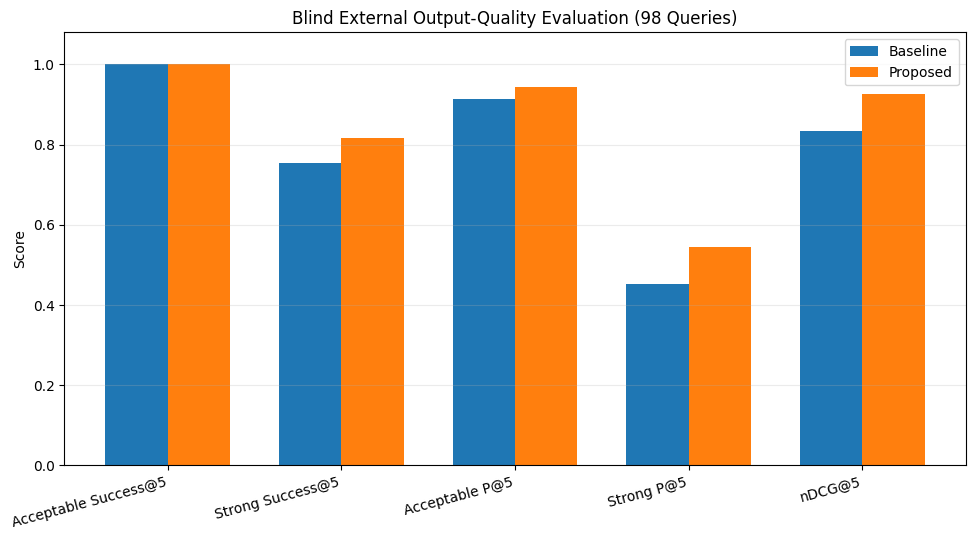

In [10]:
# Figure for paper.
plot_metrics = [
    ("Acceptable Success@5", "acceptable_success_at_5"),
    ("Strong Success@5", "strong_success_at_5"),
    ("Acceptable P@5", "acceptable_p_at_5"),
    ("Strong P@5", "strong_p_at_5"),
    ("nDCG@5", "ndcg_at_5"),
]
plot_df = summary.set_index("system")
x = np.arange(len(plot_metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(
    x - width / 2,
    [plot_df.loc["baseline", c] for _, c in plot_metrics],
    width,
    label="Baseline",
)
ax.bar(
    x + width / 2,
    [plot_df.loc["proposed", c] for _, c in plot_metrics],
    width,
    label="Proposed",
)
ax.set_xticks(x)
ax.set_xticklabels([a for a, _ in plot_metrics], rotation=15, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title("Blind External Output-Quality Evaluation (98 Queries)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("external_eval_results_bar_v4_3_FINAL.png", dpi=180, bbox_inches="tight")
plt.show()